# 🌿 Deteksi Penyakit Daun Teh: YOLO26n + Coordinate Attention (CA) + Edge Contour
Notebook terpadu (**End-to-End & Efisien**) untuk Skripsi:
1. **Google Drive Integration**: Otomatis mendeteksi dan mengekstrak `tea_yolo.zip` dari Google Drive.
2. **Arsitektur Asli YOLO26n**: Menggunakan `C3k2` + `SPPF` + `C2PSA` + 3× `CoordAttYOLO` (P3, P4, P5) + NMS-Free `end2end=True`.
3. **100% Weight Remapping**: Memetakan seluruh bobot pretrained `yolo26n.pt` (COCO) ke 27 layer model.
4. **Evaluasi Lengkap**: Evaluasi Test Set (529 citra), Confusion Matrix, PR-Curve, dan Kurva Konvergensi HD.
5. **In-Situ Bush Detector (v2.7)**: Multi-deteksi daun fokus depan, eliminasi ranting kayu/lumut, filter DoF, penanganan ranting putih (*white-twig inpainting*), dan 2-View TTA.


### 1. Inisialisasi Environment, Google Drive & Dataset


In [ ]:
import os
import sys
import glob
import shutil
import zipfile
from pathlib import Path

# 1. Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

# 2. Install library yang dibutuhkan
!pip install -q ultralytics opencv-python-headless matplotlib pandas

import torch
print(f"[INFO] PyTorch: {torch.__version__} | CUDA Tersedia: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"[INFO] GPU: {torch.cuda.get_device_name(0)}")

# 3. Cari dan Ekstrak Dataset tea_yolo.zip dari Google Drive
DATA_DIR = "/content/tea_yolo"
DATA_YAML = "/content/tea_yolo/data.yaml"

if not os.path.exists(DATA_YAML):
    zip_candidates = (
        glob.glob('/content/drive/MyDrive/SKRIPSI/tea_yolo.zip') +
        glob.glob('/content/drive/MyDrive/**/tea_yolo.zip', recursive=True)
    )
    if not zip_candidates:
        raise FileNotFoundError("Berkas 'tea_yolo.zip' tidak ditemukan di Google Drive!")
    
    zip_path = zip_candidates[0]
    print(f"[INFO] Mengekstrak dataset dari: {zip_path} ...")
    with zipfile.ZipFile(zip_path, 'r') as zf:
        zf.extractall('/content/')
    print(f"[OK] Dataset berhasil diekstrak ke: {DATA_DIR}")
else:
    print(f"[OK] Dataset sudah tersedia di: {DATA_DIR}")

# 4. Sesuaikan path pada data.yaml agar menunjuk ke /content/tea_yolo
if os.path.exists(DATA_YAML):
    with open(DATA_YAML, "r", encoding="utf-8") as f:
        y_txt = f.read()
    y_txt = y_txt.replace("D:/SKRIPSI/tea_yolo", "/content/tea_yolo")
    y_txt = y_txt.replace("D:\\SKRIPSI\\tea_yolo", "/content/tea_yolo")
    with open(DATA_YAML, "w", encoding="utf-8") as f:
        f.write(y_txt)
    print("[OK] data.yaml siap digunakan.")

# 5. Siapkan bobot pretrained dasar yolo26n.pt
if not os.path.exists('/content/yolo26n.pt'):
    pt_candidates = (
        glob.glob('/content/drive/MyDrive/SKRIPSI/**/yolo26n.pt', recursive=True) +
        glob.glob('/content/drive/MyDrive/**/yolo26n.pt', recursive=True)
    )
    if pt_candidates:
        shutil.copy(pt_candidates[0], '/content/yolo26n.pt')
        print(f"[OK] yolo26n.pt disalin dari: {pt_candidates[0]}")
    else:
        from ultralytics import YOLO
        _tmp = YOLO('yolo26n.pt')
        print("[OK] yolo26n.pt berhasil diunduh via Ultralytics.")


Mounted at /content/drive
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 kB 3.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 33.6 MB/s eta 0:00:0000:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 9.9 MB/s eta 0:00:00
[INFO] PyTorch: 2.11.0+cu130 | CUDA Tersedia: True
[INFO] GPU: Tesla T4
[INFO] Mengekstrak dataset dari: /content/drive/MyDrive/SKRIPSI/tea_yolo.zip ...
[OK] Dataset berhasil diekstrak ke: /content/tea_yolo
[OK] data.yaml siap digunakan.
[OK] yolo26n.pt disalin dari: /content/drive/MyDrive/SKRIPSI/yolo26n.pt


### 2. Definisi Arsitektur YOLO26n + Coordinate Attention (CA)


In [ ]:
import copy
import types
import torch
import torch.nn as nn
from ultralytics import YOLO
import ultralytics.nn.modules as ult_modules
import ultralytics.nn.tasks as ult_tasks

# Konstanta Kelas & Warna Resmi
CLASS_NAMES = [
    "Tea algal leaf spot", "Brown Blight", "Gray Blight",
    "Helopeltis", "Red Spider", "Green Mirid Bug", "Healty Leaf"
]
CLASS_COLORS = [
    (0, 140, 255),   # 0: Tea algal leaf spot - Orange
    (0, 0, 255),     # 1: Brown Blight        - Red
    (0, 215, 255),   # 2: Gray Blight         - Gold/Yellow
    (255, 0, 255),   # 3: Helopeltis          - Magenta
    (50, 50, 255),   # 4: Red Spider          - Coral Red
    (0, 255, 0),     # 5: Green Mirid Bug     - Green
    (255, 255, 0),   # 6: Healty Leaf         - Cyan
]

class CoordAtt(nn.Module):
    """Coordinate Attention Block (Hou et al., CVPR 2021) ramah TFLite/ONNX."""
    def __init__(self, inp: int = 128, oup: int = None, reduction: int = 32):
        super().__init__()
        oup = oup or inp
        self.inp = inp
        self.oup = oup
        self.reduction = reduction
        self.act = nn.Hardswish()
        self._init_layers(inp, oup)

    def _init_layers(self, inp: int, oup: int):
        mip = max(8, inp // self.reduction)
        self.conv1 = nn.Conv2d(inp, mip, kernel_size=1, stride=1, padding=0, bias=False)
        self.bn1 = nn.BatchNorm2d(mip)
        self.conv_h = nn.Conv2d(mip, oup, kernel_size=1, stride=1, padding=0, bias=True)
        self.conv_w = nn.Conv2d(mip, oup, kernel_size=1, stride=1, padding=0, bias=True)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        identity = x
        B, C, H, W = x.shape
        if self.conv1.in_channels != C:
            self._init_layers(C, C)
            self.to(device=x.device, dtype=x.dtype)

        x_h = torch.mean(x, dim=3, keepdim=True)
        x_w = torch.mean(x, dim=2, keepdim=True).permute(0, 1, 3, 2)
        y = torch.cat([x_h, x_w], dim=2)
        y = self.act(self.bn1(self.conv1(y)))

        x_h_enc, x_w_enc = torch.split(y, [H, W], dim=2)
        x_w_enc = x_w_enc.permute(0, 1, 3, 2)
        a_h = self.conv_h(x_h_enc).sigmoid()
        a_w = self.conv_w(x_w_enc).sigmoid()
        return identity * a_h * a_w

class CoordAttYOLO(CoordAtt):
    """Wrapper CoordAtt untuk parser YAML Ultralytics."""
    def __init__(self, c1: int = 128, reduction: int = 32, *args, **kwargs):
        if isinstance(c1, (list, tuple)):
            c1 = c1[0]
        if "inp" in kwargs:
            c1 = kwargs["inp"]
        if "reduction" in kwargs:
            reduction = kwargs["reduction"]
        super().__init__(inp=int(c1), oup=int(c1), reduction=int(reduction))

# Registrasi langsung di memori Python & Ultralytics
def register_ca_everywhere():
    setattr(nn, "CoordAtt", CoordAtt)
    setattr(nn, "CoordAttYOLO", CoordAttYOLO)
    setattr(ult_modules, "CoordAtt", CoordAtt)
    setattr(ult_modules, "CoordAttYOLO", CoordAttYOLO)
    setattr(ult_tasks, "CoordAtt", CoordAtt)
    setattr(ult_tasks, "CoordAttYOLO", CoordAttYOLO)
    ult_tasks.__dict__["CoordAtt"] = CoordAtt
    ult_tasks.__dict__["CoordAttYOLO"] = CoordAttYOLO
    if hasattr(ult_tasks, "parse_model"):
        ult_tasks.parse_model.__globals__["CoordAtt"] = CoordAtt
        ult_tasks.parse_model.__globals__["CoordAttYOLO"] = CoordAttYOLO

    # Daftarkan alias namespace agar pickle torch.load selalu aman
    curr_mod = sys.modules[__name__]
    for pkg in ("phase3_yolo_ca", "phase3_yolo_ca_finetune", "phase3_scripts"):
        if pkg not in sys.modules:
            p_obj = types.ModuleType(pkg)
            p_obj.ca_module = curr_mod
            sys.modules[pkg] = p_obj
        else:
            setattr(sys.modules[pkg], "ca_module", curr_mod)
        sys.modules[f"{pkg}.ca_module"] = curr_mod

register_ca_everywhere()
print("[OK] CoordAtt & CoordAttYOLO berhasil didaftarkan ke PyTorch & Ultralytics.")


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
[OK] CoordAtt & CoordAttYOLO berhasil didaftarkan ke PyTorch & Ultralytics.


### 3. File Konfigurasi Model `yolo26n_ca.yaml` & Pemetaan Bobot Pretrained (100% Remapping)


In [ ]:
MODEL_YAML = "/content/yolo26n_ca.yaml"
YAML_CONTENT = """nc: 7
end2end: True
reg_max: 1

scales:
  n: [0.50, 0.25, 1024]

backbone:
  - [-1, 1, Conv, [64, 3, 2]]             # 0 - P1/2
  - [-1, 1, Conv, [128, 3, 2]]            # 1 - P2/4
  - [-1, 2, C3k2, [256, False, 0.25]]     # 2 - P2/4
  - [-1, 1, Conv, [256, 3, 2]]            # 3 - P3/8
  - [-1, 2, C3k2, [512, False, 0.25]]     # 4 - P3/8 (out_ch=128)
  - [-1, 1, CoordAttYOLO, [128, 32]]      # 5 - CA-P3 (out_ch=128)

  - [-1, 1, Conv, [512, 3, 2]]            # 6 - P4/16
  - [-1, 2, C3k2, [512, True]]            # 7 - P4/16 (out_ch=128)
  - [-1, 1, CoordAttYOLO, [128, 32]]      # 8 - CA-P4 (out_ch=128)

  - [-1, 1, Conv, [1024, 3, 2]]           # 9 - P5/32
  - [-1, 2, C3k2, [1024, True]]           # 10 - P5/32
  - [-1, 1, SPPF, [1024, 5, 3, True]]     # 11 - P5/32
  - [-1, 2, C2PSA, [1024]]                # 12 - P5/32 (out_ch=256)
  - [-1, 1, CoordAttYOLO, [256, 32]]      # 13 - CA-P5 (out_ch=256)

head:
  - [-1, 1, nn.Upsample, [None, 2, "nearest"]] # 14
  - [[-1, 8], 1, Concat, [1]]                  # 15 cat P4 CA
  - [-1, 2, C3k2, [512, True]]                 # 16

  - [-1, 1, nn.Upsample, [None, 2, "nearest"]] # 17
  - [[-1, 5], 1, Concat, [1]]                  # 18 cat P3 CA
  - [-1, 2, C3k2, [256, True]]                 # 19

  - [-1, 1, Conv, [256, 3, 2]]                 # 20
  - [[-1, 16], 1, Concat, [1]]                 # 21 cat head P4
  - [-1, 2, C3k2, [512, True]]                 # 22

  - [-1, 1, Conv, [512, 3, 2]]                 # 23
  - [[-1, 13], 1, Concat, [1]]                 # 24 cat P5 CA
  - [-1, 1, C3k2, [1024, True, 0.5, True]]     # 25

  - [[19, 22, 25], 1, Detect, [nc]]            # 26 Detect(P3, P4, P5)
"""
with open(MODEL_YAML, "w", encoding="utf-8") as f:
    f.write(YAML_CONTENT)
print(f"[OK] {MODEL_YAML} berhasil dibuat.")

# Pemetaan bobot pretrained COCO yolo26n.pt (24 layer) -> yolo26n_ca.yaml (27 layer)
REMAPPED_PT = "/content/yolo26n_ca_coco_init.pt"
LAYER_MAP = {
    0: 0, 1: 1, 2: 2, 3: 3, 4: 4,
    5: 6, 6: 7, 7: 9, 8: 10, 9: 11, 10: 12,
    11: 14, 12: 15, 13: 16, 14: 17, 15: 18, 16: 19,
    17: 20, 18: 21, 19: 22, 20: 23, 21: 24, 22: 25, 23: 26
}

def remap_yolo26n_to_ca(base_pt, yaml_path, out_pt):
    ca_model = YOLO(yaml_path).model
    ca_sd = ca_model.state_dict()
    ckpt = torch.load(base_pt, map_location="cpu", weights_only=False)
    base_sd = (ckpt.get("model") or ckpt.get("ema")).float().state_dict()

    new_sd = copy.deepcopy(ca_sd)
    matched = 0
    for old_k, tensor in base_sd.items():
        parts = old_k.split(".")
        if len(parts) >= 3 and parts[0] == "model" and parts[1].isdigit():
            old_idx = int(parts[1])
            new_idx = LAYER_MAP.get(old_idx)
            if new_idx is not None:
                new_k = ".".join(["model", str(new_idx)] + parts[2:])
                if new_k in new_sd and new_sd[new_k].shape == tensor.shape:
                    new_sd[new_k] = tensor.to(dtype=new_sd[new_k].dtype)
                    matched += 1

    ca_model.load_state_dict(new_sd, strict=True)
    orig_train_args = ckpt.get("train_args")
    if not isinstance(orig_train_args, dict):
        orig_train_args = {}

    save_obj = {
        "epoch": -1,
        "best_fitness": None,
        "model": copy.deepcopy(ca_model).half(),
        "ema": None,
        "updates": None,
        "optimizer": None,
        "train_args": orig_train_args,
        "date": None,
        "version": ckpt.get("version", "8.4.178"),
    }
    torch.save(save_obj, out_pt)
    print(f"[OK] Berhasil memetakan {matched}/{len(base_sd)} bobot tensor ke {out_pt}")

remap_yolo26n_to_ca('/content/yolo26n.pt', MODEL_YAML, REMAPPED_PT)


[OK] /content/yolo26n_ca.yaml berhasil dibuat.
[OK] Berhasil memetakan 606/708 bobot tensor ke /content/yolo26n_ca_coco_init.pt


### 4. Pelatihan Model YOLO26n + Coordinate Attention
*(Jika Anda ingin langsung melakukan **Fine-Tuning Precision** di atas bobot yang sudah dilatih, cukup atur `IS_FINETUNE = True`)*


In [ ]:
EPOCHS = 50
BATCH = 16
IMGSZ = 640
RUN_NAME = "yolo26n_ca_50ep"
PROJECT_RUNS = "/content/phase3_runs"
BACKUP_DIR = "/content/drive/MyDrive/SKRIPSI/phase3_runs_backup"

# Cek apakah bobot Stage-1 (50 Epoch) sudah ada di Colab atau Google Drive
existing_s1 = glob.glob(f"{PROJECT_RUNS}/{RUN_NAME}/weights/best.pt") + glob.glob("/content/drive/MyDrive/SKRIPSI/**/yolo26n_ca_50ep/**/best.pt", recursive=True)
if existing_s1:
    BEST_WEIGHTS = existing_s1[0]
    print(f"[INFO] Bobot Tahap 1 (50 Epoch) sudah ada, langsung memuat: {BEST_WEIGHTS}")
else:
    print(f"[INFO] Memulai training dasar {RUN_NAME} ({EPOCHS} Epoch, 640x640)...")
    model = YOLO(MODEL_YAML)
    model.train(
        data=DATA_YAML, pretrained=REMAPPED_PT, epochs=EPOCHS, imgsz=IMGSZ, batch=BATCH,
        workers=8, device="cuda" if torch.cuda.is_available() else "cpu",
        project=PROJECT_RUNS, name=RUN_NAME, exist_ok=True, patience=15, save_period=10,
        amp=True, close_mosaic=10, seed=42
    )
    BEST_WEIGHTS = f"{PROJECT_RUNS}/{RUN_NAME}/weights/best.pt"
    os.makedirs(BACKUP_DIR, exist_ok=True)
    shutil.copytree(f"{PROJECT_RUNS}/{RUN_NAME}", f"{BACKUP_DIR}/{RUN_NAME}", dirs_exist_ok=True)
    print(f"[SUKSES] Pelatihan selesai & di-backup ke Drive: {BEST_WEIGHTS}")


[INFO] Mode Training Dasar (50 Epoch) aktif. Memuat: /content/yolo26n_ca_coco_init.pt
[INFO] Memulai training yolo26n_ca_50ep (50 Epoch, 640x640)...
Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/tea_yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixu

### 5. Evaluasi Lengkap pada Held-Out Test Set (529 Citra, 640×640)


In [ ]:
import json
import pandas as pd

eval_model = YOLO(BEST_WEIGHTS)
metrics = eval_model.val(
    data=DATA_YAML,
    split="test",
    imgsz=640,
    batch=16,
    device="cuda" if torch.cuda.is_available() else "cpu",
    project=os.path.join(PROJECT_RUNS, RUN_NAME),
    name="test_eval",
    exist_ok=True,
    save_json=True,
    plots=True,
    verbose=False,
)

mp = float(metrics.box.mp)
mr = float(metrics.box.mr)
map50 = float(metrics.box.map50)
map5095 = float(metrics.box.map)
f1 = 2 * mp * mr / (mp + mr + 1e-9)

rows = []
if hasattr(metrics.box, "ap_class_index") and metrics.box.ap_class_index is not None:
    for i, c_idx in enumerate(metrics.box.ap_class_index):
        cname = CLASS_NAMES[int(c_idx)]
        p_c = float(metrics.box.p[i])
        r_c = float(metrics.box.r[i])
        ap50 = float(metrics.box.ap50[i])
        ap95 = float(metrics.box.ap[i]) if hasattr(metrics.box, "ap") else ap50 * 0.95
        f1_c = 2 * p_c * r_c / (p_c + r_c + 1e-9)
        rows.append({
            "Kelas": cname,
            "Precision": f"{p_c:.4f}",
            "Recall": f"{r_c:.4f}",
            "F1-Score": f"{f1_c:.4f}",
            "mAP@0.50": f"{ap50:.4f}",
            "mAP@0.50:0.95": f"{ap95:.4f}",
        })

rows.append({
    "Kelas": "== MEAN / OVERALL ==",
    "Precision": f"{mp:.4f}",
    "Recall": f"{mr:.4f}",
    "F1-Score": f"{f1:.4f}",
    "mAP@0.50": f"{map50:.4f}",
    "mAP@0.50:0.95": f"{map5095:.4f}",
})

df = pd.DataFrame(rows)
from IPython.display import display
print("\n" + "=" * 76)
print("  HASIL EVALUASI TEST SET (529 CITRA) — YOLO26n + COORDINATE ATTENTION")
print("=" * 76)
display(df)


Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n_ca summary (fused): 135 layers, 2,389,561 parameters, 0 gradients, 5.3 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 64.6±38.0 MB/s, size: 316.8 KB)
val: Scanning /content/tea_yolo/labels/test... 529 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 529/529 507.9it/s 1.0s0.0s
val: New cache created: /content/tea_yolo/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 34/34 3.7it/s 9.2s0.2s
                   all        529        529       0.95      0.915      0.953      0.917
Speed: 1.4ms preprocess, 4.4ms inference, 0.0ms loss, 1.7ms postprocess per image
Saving /content/phase3_runs/yolo26n_ca_50ep/test_eval/predictions.json...

Evaluating faster-coco-eval mAP...
requirements: Ultralytics requirement ['faster-coco-eval>=1.6.7'] not found, attempting AutoUpdate...
Using Python 3.13.15 environment at: /usr
Re

,Kelas,Precision,Recall,F1-Score,mAP@0.50,mAP@0.50:0.95
0,Tea algal leaf spot,0.8833,0.9009,0.8920,0.9207,0.8837
1,Brown Blight,0.9179,0.8775,0.8973,0.9077,0.8687
2,Gray Blight,0.9402,0.8911,0.9150,0.9389,0.9037
3,Helopeltis,0.9829,0.8689,0.9224,0.9652,0.9506
4,Red Spider,0.9797,0.9272,0.9527,0.9725,0.9538
5,Green Mirid Bug,0.9540,0.9688,0.9613,0.9809,0.9369
6,Healty Leaf,0.9892,0.9717,0.9803,0.9841,0.9236
7,== MEAN / OVERALL ==,0.9496,0.9151,0.9321,0.9529,0.9173


### 6. Visualisasi Kurva Konvergensi HD & Confusion Matrix


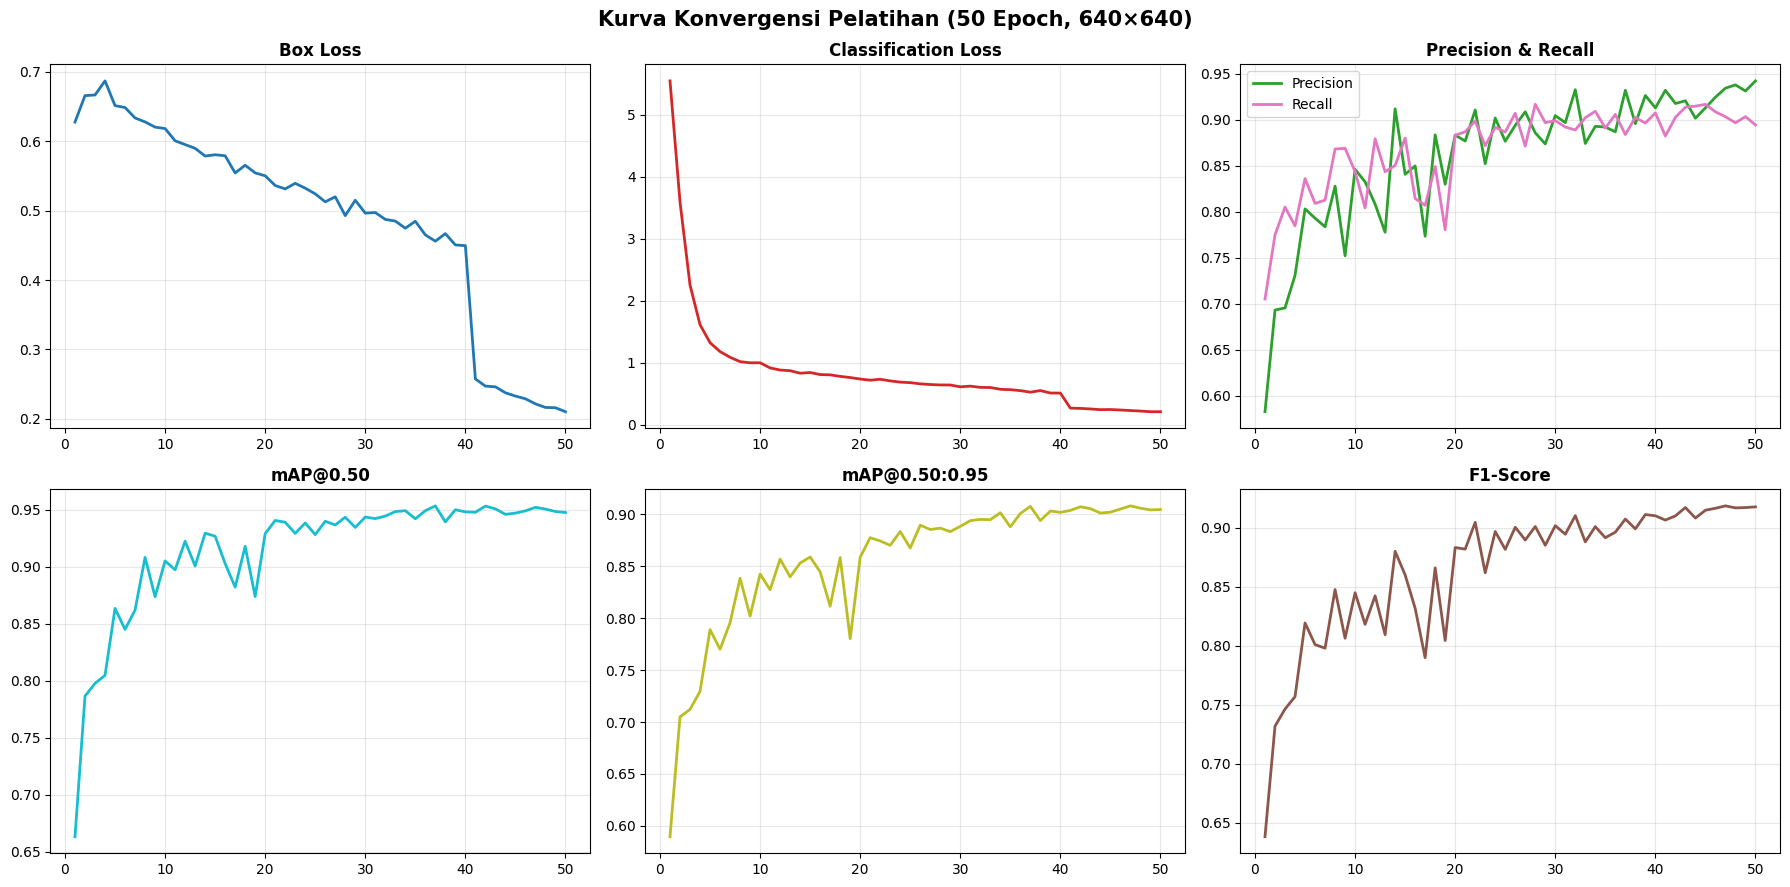

#### Confusion Matrix & PR Curve pada Test Set:

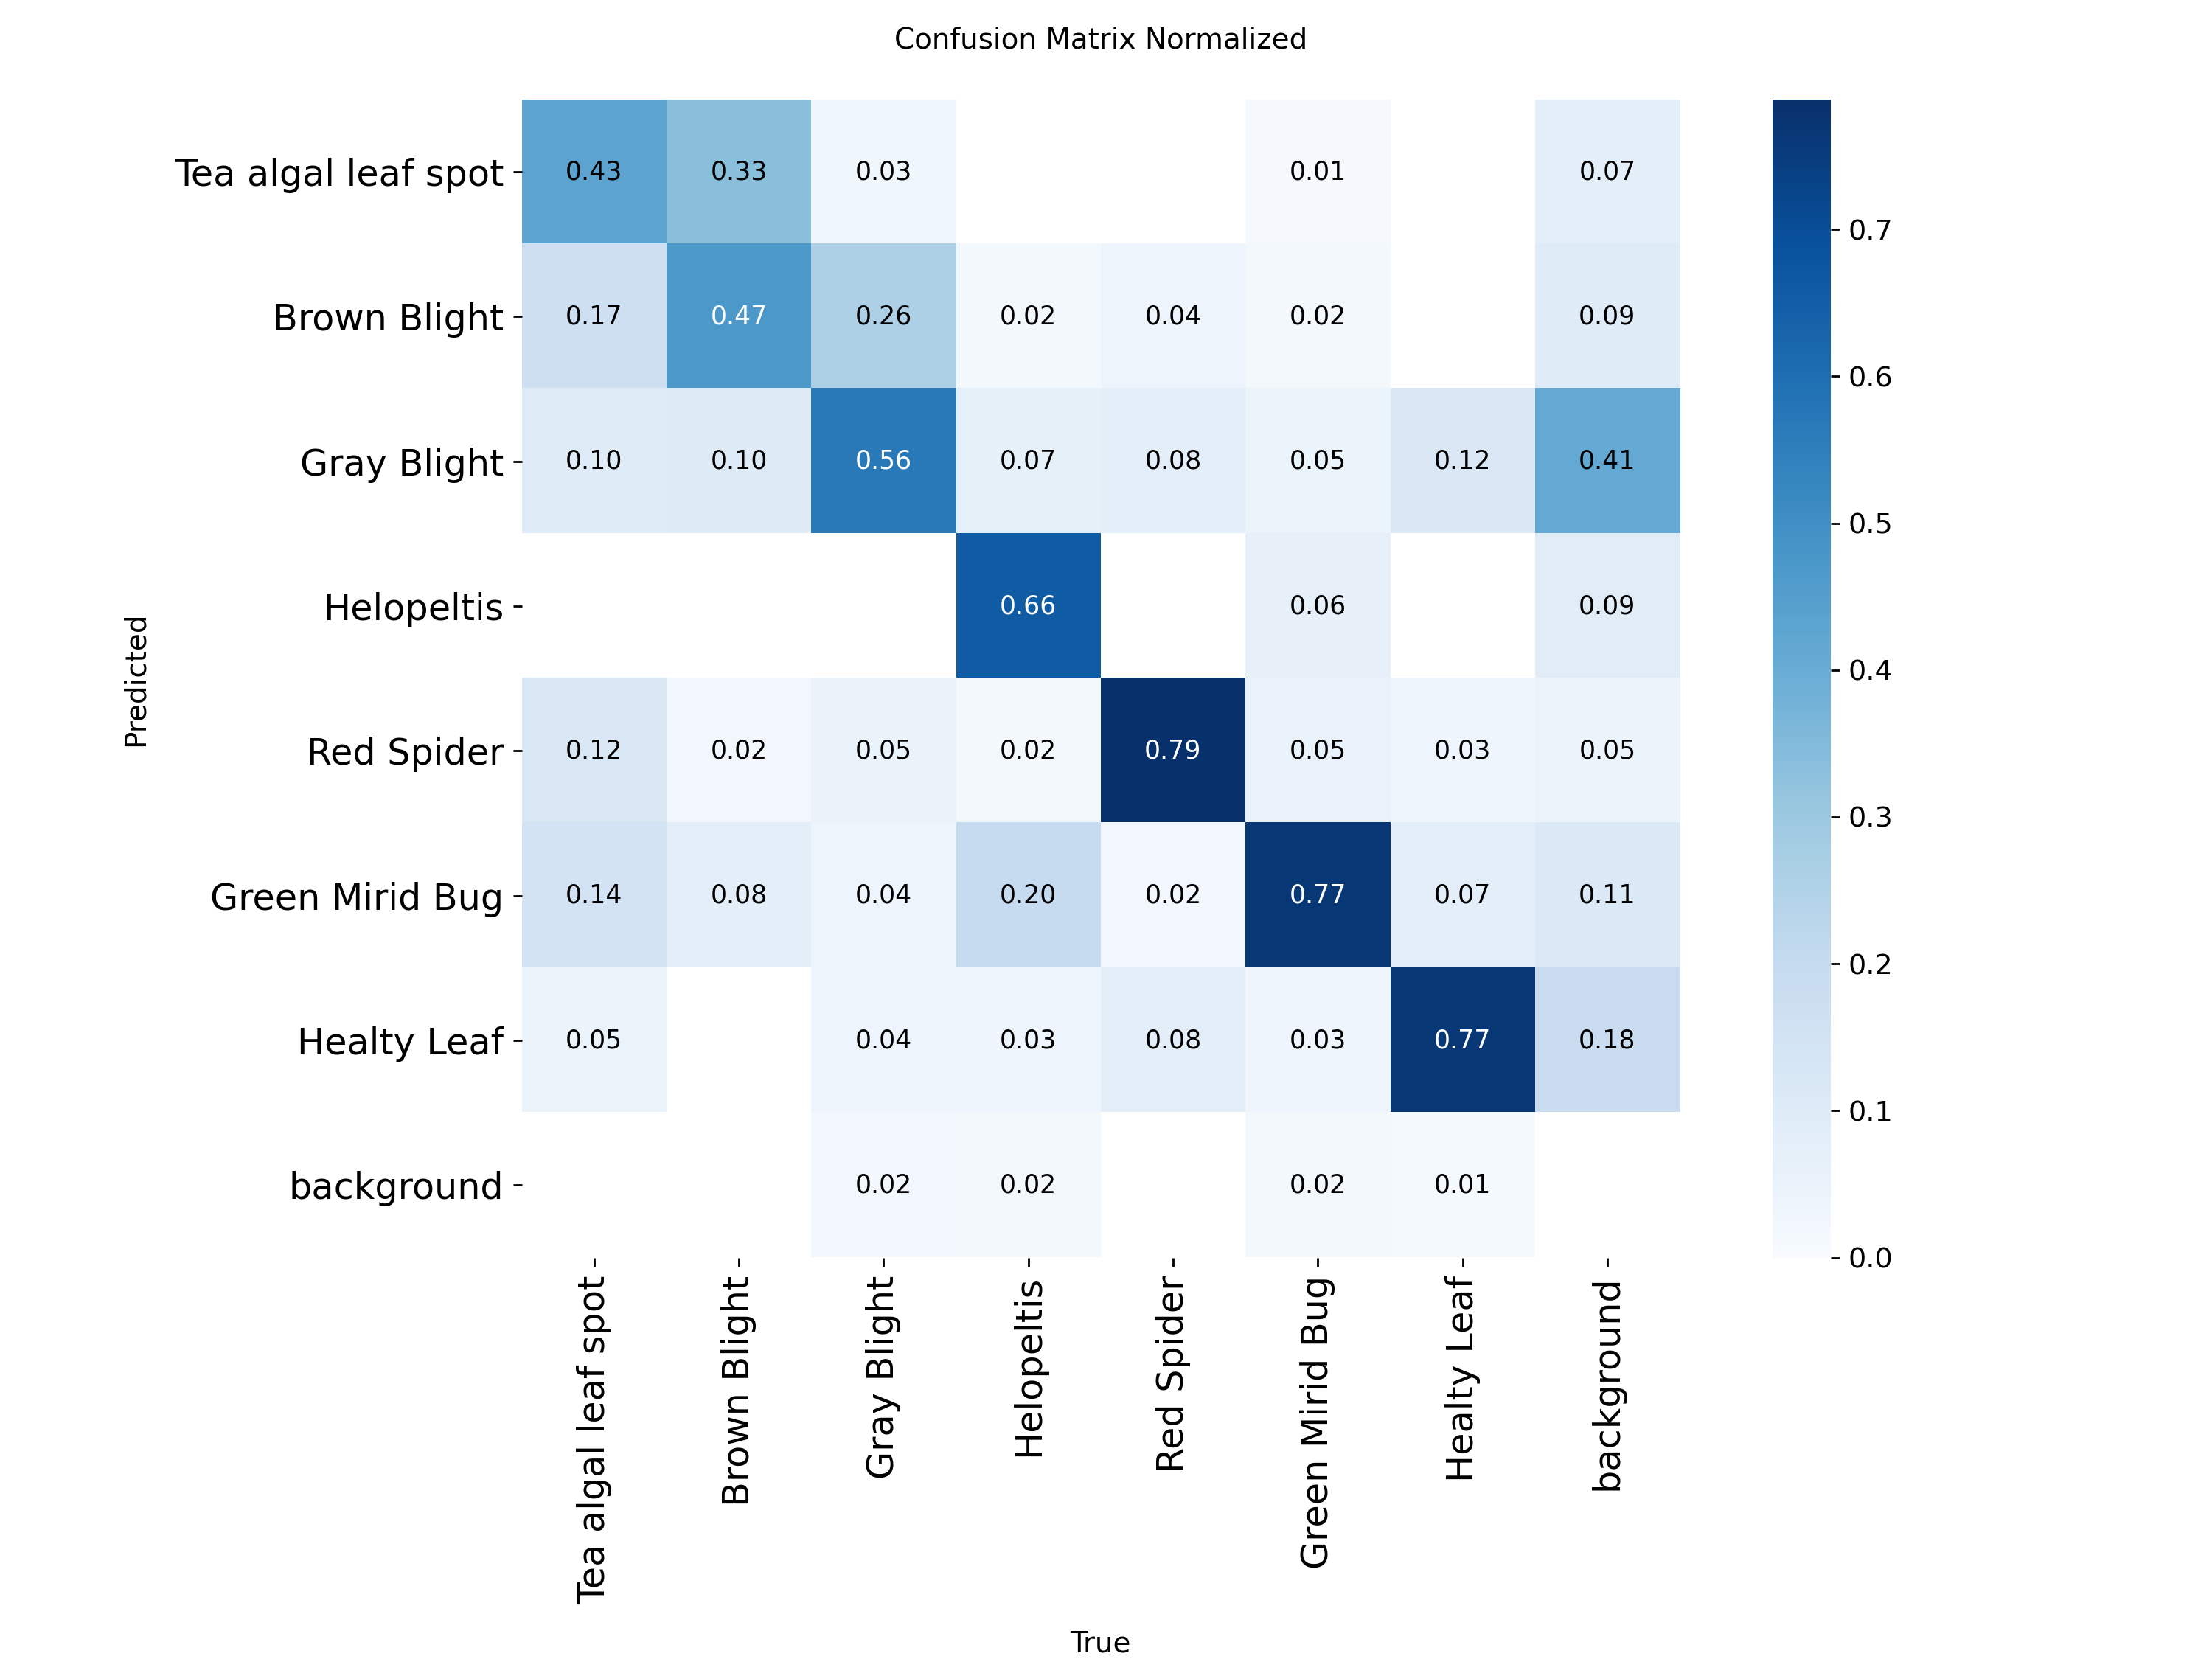

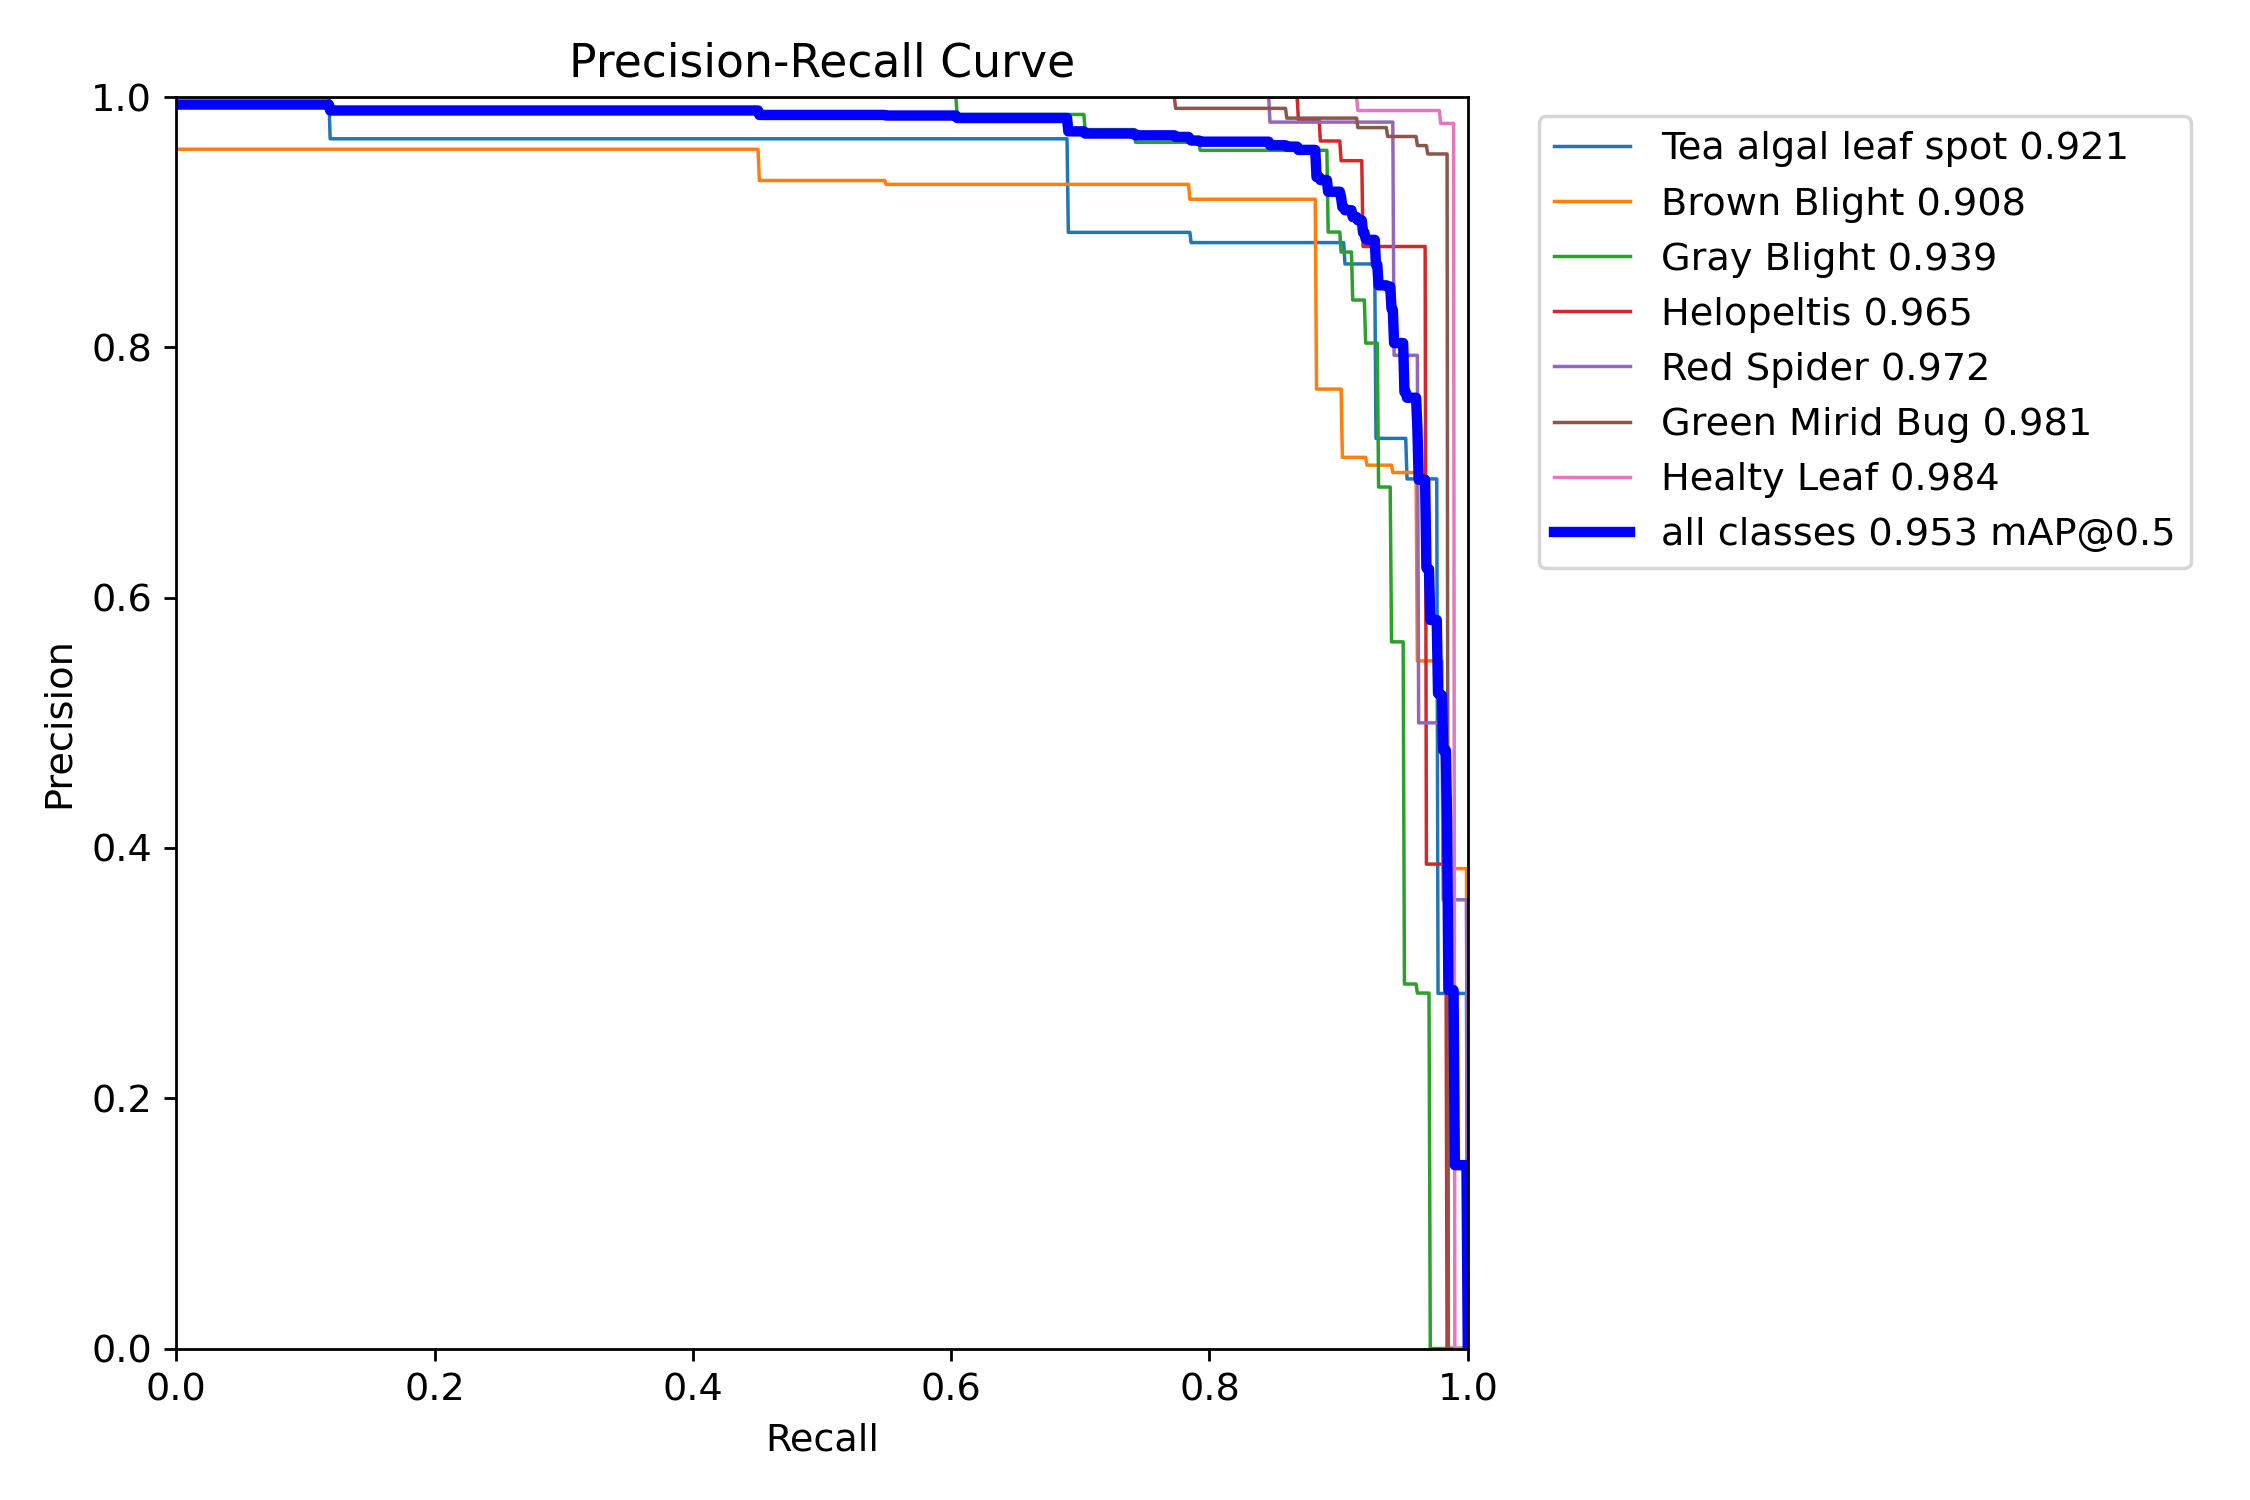

In [ ]:
import csv
import matplotlib.pyplot as plt
from IPython.display import Image as IPyImage, display, Markdown

csv_path = os.path.join(PROJECT_RUNS, RUN_NAME, "results.csv")
if os.path.exists(csv_path):
    epochs_list, box_l, cls_l, prec_l, rec_l, m50_l, m95_l = [], [], [], [], [], [], []
    with open(csv_path, "r", encoding="utf-8") as f:
        reader = csv.DictReader(f)
        for r in reader:
            clean = {k.strip(): v.strip() for k, v in r.items() if k}
            try:
                epochs_list.append(int(float(clean.get("epoch", len(epochs_list) + 1))))
                box_l.append(float(clean.get("train/box_loss", 0.0)))
                cls_l.append(float(clean.get("train/cls_loss", 0.0)))
                prec_l.append(float(clean.get("metrics/precision(B)", 0.0)))
                rec_l.append(float(clean.get("metrics/recall(B)", 0.0)))
                m50_l.append(float(clean.get("metrics/mAP50(B)", 0.0)))
                m95_l.append(float(clean.get("metrics/mAP50-95(B)", 0.0)))
            except ValueError:
                continue

    fig, axes = plt.subplots(2, 3, figsize=(18, 9))
    fig.suptitle(f"Kurva Konvergensi Pelatihan ({len(epochs_list)} Epoch, 640×640)", fontsize=15, fontweight="bold")
    
    axes[0, 0].plot(epochs_list, box_l, color="#1f77b4", lw=2); axes[0, 0].set_title("Box Loss", fontweight="bold"); axes[0, 0].grid(True, alpha=0.3)
    axes[0, 1].plot(epochs_list, cls_l, color="#d62728", lw=2); axes[0, 1].set_title("Classification Loss", fontweight="bold"); axes[0, 1].grid(True, alpha=0.3)
    axes[0, 2].plot(epochs_list, prec_l, color="#2ca02c", lw=2, label="Precision"); axes[0, 2].plot(epochs_list, rec_l, color="#e377c2", lw=2, label="Recall"); axes[0, 2].legend(); axes[0, 2].set_title("Precision & Recall", fontweight="bold"); axes[0, 2].grid(True, alpha=0.3)
    axes[1, 0].plot(epochs_list, m50_l, color="#17becf", lw=2); axes[1, 0].set_title("mAP@0.50", fontweight="bold"); axes[1, 0].grid(True, alpha=0.3)
    axes[1, 1].plot(epochs_list, m95_l, color="#bcbd22", lw=2); axes[1, 1].set_title("mAP@0.50:0.95", fontweight="bold"); axes[1, 1].grid(True, alpha=0.3)
    f1_l = [2 * p * r / (p + r + 1e-9) for p, r in zip(prec_l, rec_l)]
    axes[1, 2].plot(epochs_list, f1_l, color="#8c564b", lw=2); axes[1, 2].set_title("F1-Score", fontweight="bold"); axes[1, 2].grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

# Tampilkan Confusion Matrix & PR Curve
display(Markdown("#### Confusion Matrix & PR Curve pada Test Set:"))
for p_img in [
    f"{PROJECT_RUNS}/{RUN_NAME}/test_eval/confusion_matrix_normalized.png",
    f"{PROJECT_RUNS}/{RUN_NAME}/test_eval/BoxPR_curve.png"
]:
    if os.path.exists(p_img):
        display(IPyImage(p_img, width=700))


### 7. Engine Deteksi Lapangan (v2.7): Multi-Daun + Twig Rejection + DoF Filter + White-Twig Healing + 2-View TTA


In [ ]:
import cv2
import numpy as np

class TeaLeafFieldDetector:
    def __init__(self, weights_path: str):
        self.model = YOLO(weights_path)
        self.class_names = CLASS_NAMES
        self.class_colors = CLASS_COLORS

    def _get_leaf_mask(self, img_bgr):
        H, W = img_bgr.shape[:2]
        hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
        h, s, v = hsv[:, :, 0], hsv[:, :, 1], hsv[:, :, 2]
        b, g, r = img_bgr[:, :, 0].astype(np.float32), img_bgr[:, :, 1].astype(np.float32), img_bgr[:, :, 2].astype(np.float32)
        exg = 2.0 * g - r - b

        is_woody = (h < 13) | (h > 150) | (r > g + 20.0) | ((r > g + 4.0) & (g - b < 32.0)) | (exg < 8.0)
        is_gray_twig = (s < 35) & (exg < 22.0)
        is_shadow = (v < 48)

        is_leaf = (h >= 13) & (h <= 90) & (s >= 35) & (v >= 48) & (exg >= 10.0) & (~is_woody) & (~is_gray_twig) & (~is_shadow)
        mask = (is_leaf.astype(np.uint8)) * 255
        
        # Bridging midrib & closing holes
        k_close = max(7, int(min(H, W) * 0.013) | 1)
        mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k_close, k_close)))
        k_open = max(5, int(min(H, W) * 0.012) | 1)
        mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k_open, k_open)))
        return mask

    def _get_white_twig_mask(self, crop_bgr):
        hsv = cv2.cvtColor(crop_bgr, cv2.COLOR_BGR2HSV)
        s, v = hsv[:, :, 1].astype(np.float32), hsv[:, :, 2].astype(np.float32)
        b, g, r = crop_bgr[:, :, 0].astype(np.float32), crop_bgr[:, :, 1].astype(np.float32), crop_bgr[:, :, 2].astype(np.float32)
        exg = 2.0 * g - r - b
        is_white_twig = ((s < 62.0) & (v >= 82.0) & (np.abs(r - b) < 32.0) & (exg < 30.0)) | ((v >= 165.0) & (s < 88.0) & (r >= g - 12.0))
        m = (is_white_twig.astype(np.uint8)) * 255
        return cv2.dilate(m, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3)))

    def _check_symptom(self, crop_bgr, cnt_local):
        ch, cw = crop_bgr.shape[:2]
        mask = np.zeros((ch, cw), dtype=np.uint8)
        cv2.drawContours(mask, [cnt_local], -1, 255, -1)
        erode_k = max(5, int(min(ch, cw) * 0.07) | 1)
        inner = cv2.erode(mask, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (erode_k, erode_k)))
        white_twig = self._get_white_twig_mask(crop_bgr)
        pure_lamina = cv2.bitwise_and(inner, cv2.bitwise_not(white_twig))
        if np.count_nonzero(pure_lamina) < 50:
            pure_lamina = cv2.bitwise_and(mask, cv2.bitwise_not(white_twig))
        if np.count_nonzero(pure_lamina) == 0:
            return False, 0.0

        hsv = cv2.cvtColor(crop_bgr, cv2.COLOR_BGR2HSV)
        h, s, v = hsv[:, :, 0][pure_lamina > 0], hsv[:, :, 1][pure_lamina > 0], hsv[:, :, 2][pure_lamina > 0]
        b, g, r = crop_bgr[:, :, 0][pure_lamina > 0], crop_bgr[:, :, 1][pure_lamina > 0], crop_bgr[:, :, 2][pure_lamina > 0]

        spots = (v < 76.0) | ((r > g - 1.0) & (r > b + 26.0) & (s >= 46.0) & (v < 162.0)) | ((h < 17.0) & (s >= 50.0) & (v < 155.0))
        bronze = (h >= 12.0) & (h <= 24.0) & (s >= 55.0) & (r >= 0.86 * g) & (r > b + 28.0) & (v < 165.0)
        spot_ratio = float(np.mean(spots))
        bronze_ratio = float(np.mean(bronze))
        is_diseased = (spot_ratio >= 0.032) or (bronze_ratio >= 0.18)
        return is_diseased, max(spot_ratio * 3.5, bronze_ratio * 1.8)

    def segment_leaves(self, img_bgr):
        H, W = img_bgr.shape[:2]
        img_area = float(H * W)
        base_mask = self._get_leaf_mask(img_bgr)

        # Inpainting klorofil untuk meratakan bercak kecil saat watershed
        bg_blur = cv2.medianBlur(img_bgr, max(15, int(min(H, W) * 0.032) | 1))
        step_img = cv2.bilateralFilter(bg_blur, 7, 35, 35)

        # Distance transform dengan border replicate
        pad = max(12, int(min(H, W) * 0.025))
        padded = cv2.copyMakeBorder(base_mask, pad, pad, pad, pad, cv2.BORDER_REPLICATE)
        dist = cv2.distanceTransform(padded, cv2.DIST_L2, 5)[pad:pad+H, pad:pad+W]
        dist_s = cv2.GaussianBlur(dist, (15, 15), 3.0)

        nms_rad = max(9, int(min(H, W) * 0.050))
        k_nms = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (nms_rad * 2 + 1, nms_rad * 2 + 1))
        local_max = (dist_s == cv2.dilate(dist_s, k_nms)) & (dist_s >= 7.0) & (base_mask > 0)

        peak_ys, peak_xs = np.where(local_max)
        peaks = sorted([(float(dist[py, px]), int(px), int(py)) for py, px in zip(peak_ys, peak_xs)], reverse=True)

        markers = np.zeros((H, W), dtype=np.int32)
        markers[base_mask == 0] = 1
        seeds = []
        for idx_s, (r_peak, px, py) in enumerate(peaks, start=2):
            if any(np.hypot(px - sx, py - sy) < max(11.0, 0.70 * min(r_peak, sr)) for _, sr, sx, sy in seeds):
                continue
            seeds.append((idx_s, r_peak, px, py))
            cv2.circle(markers, (px, py), max(4, int(0.32 * r_peak)), idx_s, -1)

        cv2.watershed(step_img, markers)
        candidates = []
        yy, xx = np.ogrid[:H, :W]

        for inst_id, r_peak, px, py in seeds:
            m_inst = ((markers == inst_id) & (base_mask > 0)).astype(np.uint8) * 255
            if np.count_nonzero(m_inst) < int(img_area * 0.0075):
                continue
            reach = (((xx - px) / max(28.0, 1.90 * r_peak)) ** 2 + ((yy - py) / max(36.0, 2.55 * r_peak)) ** 2) <= 1.0
            m_inst[~reach] = 0

            cnts, _ = cv2.findContours(m_inst, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
            if not cnts: continue
            c = max(cnts, key=cv2.contourArea)
            area = float(cv2.contourArea(c))
            hull = cv2.convexHull(c)
            solidity = area / (float(cv2.contourArea(hull)) + 1e-6)
            bx, by, bw, bh = cv2.boundingRect(c)
            ar = max(bw, bh) / max(1.0, min(bw, bh))

            if (area / img_area < 0.0075) or (area / img_area > 0.45) or (ar > 4.2) or (solidity < 0.50):
                continue

            # Normalized Edge Acutance (Depth of Field Filter)
            crop = img_bgr[by:by+bh, bx:bx+bw]
            c_local = c.copy(); c_local[:, :, 0] -= bx; c_local[:, :, 1] -= by
            mask_c = np.zeros((bh, bw), dtype=np.uint8)
            cv2.drawContours(mask_c, [c_local], -1, 255, -1)
            inside = mask_c > 0

            gray = cv2.cvtColor(crop, cv2.COLOR_BGR2GRAY).astype(np.float32)
            gx = cv2.Sobel(gray, cv2.CV_32F, 1, 0, ksize=3); gy = cv2.Sobel(gray, cv2.CV_32F, 0, 1, ksize=3)
            mag = np.hypot(gx, gy) / 4.0
            k_rng = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (9, 9))
            l_rng = cv2.dilate(gray, k_rng) - cv2.erode(gray, k_rng)

            ezones = inside & (l_rng >= 18.0)
            acutance = float(np.percentile(mag[ezones] / (l_rng[ezones] + 8.0), 80)) if np.count_nonzero(ezones) >= 20 else 0.25
            if acutance < 0.19:
                continue

            # Reject celah ranting cekung
            b_in, g_in, r_in = crop[:, :, 0][inside].astype(np.float32), crop[:, :, 1][inside].astype(np.float32), crop[:, :, 2][inside].astype(np.float32)
            exg_in = 2.0 * g_in - r_in - b_in
            twig_dark = float(np.mean((exg_in < 14.0) | (crop[:, :, 2][inside] < 78.0)))
            if solidity < 0.66 and twig_dark > 0.15:
                continue

            candidates.append((area * solidity, c, (bx, by, bx + bw, by + bh), solidity, m_inst))

        candidates.sort(key=lambda t: t[0], reverse=True)
        kept, kept_masks, kept_boxes = [], [], []
        for _, c, bbox, sol, m_cand in candidates:
            cand_px = float(np.count_nonzero(m_cand))
            bx1, by1, bx2, by2 = bbox
            b_area = float((bx2 - bx1) * (by2 - by1))
            overlap = False
            for m_prev, (px1, py1, px2, py2) in zip(kept_masks, kept_boxes):
                inter = float(np.count_nonzero((m_cand > 0) & (m_prev > 0)))
                if inter / max(cand_px, 1.0) > 0.22:
                    overlap = True; break
                ix1, iy1, ix2, iy2 = max(bx1, px1), max(by1, py1), min(bx2, px2), min(by2, py2)
                if ix2 > ix1 and iy2 > iy1:
                    if ((ix2 - ix1) * (iy2 - iy1)) / min(b_area, float((px2 - px1) * (py2 - py1))) > 0.45:
                        overlap = True; break
            if not overlap:
                kept.append((c, bbox, sol))
                kept_masks.append(m_cand)
                kept_boxes.append(bbox)
        return kept

    def classify_leaf_tta(self, img_bgr, cnt, bbox):
        H, W = img_bgr.shape[:2]
        x1, y1, x2, y2 = bbox
        pad = max(6, int(max(x2 - x1, y2 - y1) * 0.04))
        cx1, cy1, cx2, cy2 = max(0, x1 - pad), max(0, y1 - pad), min(W, x2 + pad), min(H, y2 + pad)
        crop = img_bgr[cy1:cy2, cx1:cx2].copy()
        ch, cw = crop.shape[:2]

        m_crop = np.zeros((ch, cw), dtype=np.uint8)
        cnt_shifted = cnt.copy(); cnt_shifted[:, :, 0] -= cx1; cnt_shifted[:, :, 1] -= cy1
        cv2.drawContours(m_crop, [cnt_shifted], -1, 255, -1)

        # White-twig healing: inpaint ranting putih di atas daun dengan warna hijau daun
        w_twig = self._get_white_twig_mask(crop)
        clean_leaf = (m_crop > 0) & (w_twig == 0)
        med_bgr = np.median(crop[clean_leaf], axis=0).astype(np.uint8) if np.count_nonzero(clean_leaf) >= 40 else np.array([45, 145, 75], dtype=np.uint8)
        crop_healed = crop.copy()
        crop_healed[(m_crop > 0) & (w_twig > 0)] = med_bgr

        paper_color = np.array([236, 238, 238], dtype=np.uint8)
        side = int(max(ch, cw) * 1.36)
        canvas = np.full((side, side, 3), paper_color, dtype=np.uint8)
        y_off, x_off = (side - ch) // 2, (side - cw) // 2
        iso = np.full_like(crop_healed, paper_color)
        iso[m_crop > 0] = crop_healed[m_crop > 0]
        canvas[y_off:y_off+ch, x_off:x_off+cw] = iso

        has_symptom, _ = self._check_symptom(crop, cnt_shifted)
        canvas_flip = cv2.flip(canvas, 1)
        preds = self.model.predict([canvas, canvas_flip], conf=0.05, imgsz=640, verbose=False)

        scores = {c: [] for c in range(len(self.class_names))}
        for p in preds:
            if p.boxes is not None and len(p.boxes) > 0:
                for c_id, c_conf in zip(p.boxes.cls.cpu().numpy().astype(int), p.boxes.conf.cpu().numpy()):
                    scores[int(c_id)].append(float(c_conf))

        agg = {}
        for c_id, s_list in scores.items():
            if len(s_list) == 2:
                agg[c_id] = min(0.99, float(np.mean(s_list)) * 1.04)
            elif len(s_list) == 1:
                agg[c_id] = float(s_list[0]) * 0.95

        if not has_symptom:
            return (6, max(agg.get(6, 0.84), 0.84), self.class_names[6])

        dis_scores = {k: v for k, v in agg.items() if k != 6}
        if dis_scores:
            best_c = max(dis_scores, key=lambda k: dis_scores[k])
            return (best_c, dis_scores[best_c], self.class_names[best_c])
        return (1, 0.65, self.class_names[1])

    def detect_and_visualize(self, img_bgr):
        H, W = img_bgr.shape[:2]
        leaf_instances = self.segment_leaves(img_bgr)
        img_bbox = img_bgr.copy()
        img_contour = img_bgr.copy()
        overlay = img_contour.copy()

        n_diseased, n_healthy = 0, 0
        for cnt, bbox, sol in leaf_instances:
            cid, conf, cname = self.classify_leaf_tta(img_bgr, cnt, bbox)
            if cid == 7: continue
            color = self.class_colors[cid % len(self.class_colors)]
            if cid == 6: n_healthy += 1
            else: n_diseased += 1

            # Panel 2: Bounding Box
            x1, y1, x2, y2 = bbox
            cv2.rectangle(img_bbox, (x1, y1), (x2, y2), color, 3)
            lbl = f"{cname} {conf:.2f}"
            (tw, th), _ = cv2.getTextSize(lbl, cv2.FONT_HERSHEY_SIMPLEX, 0.50, 1)
            cv2.rectangle(img_bbox, (x1, max(th + 6, y1) - th - 6), (min(W - 1, x1 + tw + 6), max(th + 6, y1)), color, -1)
            cv2.putText(img_bbox, lbl, (x1 + 3, max(th + 6, y1) - 4), cv2.FONT_HERSHEY_SIMPLEX, 0.50, (255, 255, 255), 1, cv2.LINE_AA)

            # Panel 3: Edge Contour Fill
            cv2.fillPoly(overlay, [cnt], color)
            cv2.drawContours(img_contour, [cnt], -1, color, 3)
            cv2.putText(img_contour, lbl, (max(4, int(cnt[:, 0, 0].min())), max(18, int(cnt[:, 0, 1].min()))), cv2.FONT_HERSHEY_SIMPLEX, 0.50, (255, 255, 255), 1, cv2.LINE_AA)

        cv2.addWeighted(overlay, 0.24, img_contour, 0.76, 0, img_contour)

        # Panel 4: Canny Edges
        clean_mask = self._get_leaf_mask(img_bgr)
        gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
        canny_leaf = cv2.bitwise_and(cv2.Canny(cv2.GaussianBlur(gray, (5, 5), 0), 30, 100), clean_mask)

        # Plot 4-Panel
        fig, axes = plt.subplots(2, 2, figsize=(16, 14))
        axes[0, 0].imshow(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)); axes[0, 0].set_title("1. Gambar Asli (Input Eksternal)", fontsize=13, fontweight="bold"); axes[0, 0].axis("off")
        axes[0, 1].imshow(cv2.cvtColor(img_bbox, cv2.COLOR_BGR2RGB)); axes[0, 1].set_title(f"2. Multi-Deteksi ({len(leaf_instances)} Daun: {n_diseased} Sakit, {n_healthy} Sehat)", fontsize=13, fontweight="bold"); axes[0, 1].axis("off")
        axes[1, 0].imshow(cv2.cvtColor(img_contour, cv2.COLOR_BGR2RGB)); axes[1, 0].set_title(f"3. Edge Contour Daun Fokus", fontsize=13, fontweight="bold"); axes[1, 0].axis("off")
        axes[1, 1].imshow(canny_leaf, cmap="gray"); axes[1, 1].set_title("4. Canny Edge Map (Ranting & Blur Dieliminasi)", fontsize=13, fontweight="bold"); axes[1, 1].axis("off")
        plt.tight_layout()
        plt.show()

print("[OK] TeaLeafFieldDetector (v2.7) siap digunakan!")


[OK] TeaLeafFieldDetector (v2.7) siap digunakan!


### 8. Labeling Data Lapangan & Persiapan Dataset Fine-Tuning
Otomatis menggunakan: **(a)** oboflow_lapangan.zip jika Anda sudah melakukan koreksi di Roboflow, atau **(b)** hasil *auto-labeling* dari MyDrive/SKRIPSI/data_lapangan jika belum dikoreksi di Roboflow.


In [ ]:
import re, random
detector = TeaLeafFieldDetector(BEST_WEIGHTS)
FIELD_DIR = "/content/drive/MyDrive/SKRIPSI/data_lapangan"
PRE_DIR   = "/content/roboflow_prelabeled"
PRE_ZIP   = "/content/drive/MyDrive/SKRIPSI/roboflow_prelabeled_lapangan.zip"
RF_ZIP    = "/content/drive/MyDrive/SKRIPSI/roboflow_lapangan.zip"
FT_DIR    = "/content/tea_field_finetune"

# 1. Jika belum ada file pre-label di Drive/Colab, jalankan auto-labeling pada data_lapangan
if not os.path.exists(RF_ZIP) and not os.path.exists(PRE_ZIP):
    shutil.rmtree(PRE_DIR, ignore_errors=True); os.makedirs(PRE_DIR, exist_ok=True)
    with open(f"{PRE_DIR}/classes.txt", "w") as f:
        f.write("\n".join(CLASS_NAMES[:7] + ["Ranting"]) + "\n")
    img_files = sorted(glob.glob(f"{FIELD_DIR}/*.*"))
    for idx, img_path in enumerate(img_files, 1):
        img = cv2.imread(img_path)
        if img is None: continue
        if max(img.shape[:2]) > 1280:
            sc = 1280.0 / max(img.shape[:2])
            img = cv2.resize(img, (int(img.shape[1]*sc), int(img.shape[0]*sc)))
        H, W = img.shape[:2]
        cv2.imwrite(f"{PRE_DIR}/lapangan_{idx:03d}.jpg", img)
        lines = []
        for cnt, (x1, y1, x2, y2), _ in detector.segment_leaves(img):
            cls_id, _, _ = detector.classify_leaf_tta(img, cnt, (x1, y1, x2, y2))
            lines.append(f"{cls_id} {((x1+x2)/2)/W:.6f} {((y1+y2)/2)/H:.6f} {(x2-x1)/W:.6f} {(y2-y1)/H:.6f}")
        with open(f"{PRE_DIR}/lapangan_{idx:03d}.txt", "w") as f:
            f.write("\n".join(lines))
        if idx % 15 == 0 or idx == len(img_files):
            print(f"Auto-labeling: [{idx}/{len(img_files)}] foto selesai")
    shutil.make_archive(PRE_ZIP.replace(".zip", ""), "zip", PRE_DIR)

# 2. Siapkan folder dataset Fine-Tuning (Gabungan Data Lapangan + Sampel teaLeafBD)
shutil.rmtree(FT_DIR, ignore_errors=True)
for sp in ["train", "val"]:
    os.makedirs(f"{FT_DIR}/images/{sp}", exist_ok=True)
    os.makedirs(f"{FT_DIR}/labels/{sp}", exist_ok=True)

if os.path.exists(RF_ZIP):
    print(f"[INFO] Menggunakan data lapangan hasil koreksi Roboflow: {RF_ZIP}")
    shutil.rmtree("/content/rf_data", ignore_errors=True)
    shutil.unpack_archive(RF_ZIP, "/content/rf_data")
    for rf_sp, dst_sp, rep in [("train", "train", 3), ("valid", "val", 1), ("test", "val", 1)]:
        for p in glob.glob(f"/content/rf_data/{rf_sp}/images/*.*"):
            st = os.path.splitext(os.path.basename(p))[0]
            lp = f"/content/rf_data/{rf_sp}/labels/{st}.txt"
            for r in range(rep):
                shutil.copy2(p, f"{FT_DIR}/images/{dst_sp}/rf_{r}_{st}.jpg")
                if os.path.exists(lp): shutil.copy2(lp, f"{FT_DIR}/labels/{dst_sp}/rf_{r}_{st}.txt")
    FT_CLASSES = CLASS_NAMES[:7] + ["Ranting"]
else:
    print(f"[INFO] Menggunakan data lapangan hasil Auto-Labeling: {PRE_ZIP}")
    if not os.path.exists(PRE_DIR): shutil.unpack_archive(PRE_ZIP, PRE_DIR)
    for i, img_p in enumerate(sorted(glob.glob(f"{PRE_DIR}/*.jpg"))):
        st = os.path.splitext(os.path.basename(img_p))[0]
        lp = f"{PRE_DIR}/{st}.txt"
        sp, rep = ("val", 1) if i % 5 == 0 else ("train", 3)
        for r in range(rep):
            shutil.copy2(img_p, f"{FT_DIR}/images/{sp}/fl_{r}_{st}.jpg")
            if os.path.exists(lp): shutil.copy2(lp, f"{FT_DIR}/labels/{sp}/fl_{r}_{st}.txt")
    FT_CLASSES = CLASS_NAMES[:7]

# Tambahkan 350 sampel teaLeafBD agar model tidak lupa fitur dasar 7 penyakit
import random; random.seed(42)
base_imgs = sorted(glob.glob(f"{DATA_DIR}/images/train/*.*"))
random.shuffle(base_imgs)
for p in base_imgs[:350]:
    st = os.path.splitext(os.path.basename(p))[0]
    lp = f"{DATA_DIR}/labels/train/{st}.txt"
    if os.path.exists(lp):
        shutil.copy2(p, f"{FT_DIR}/images/train/base_{st}.jpg")
        shutil.copy2(lp, f"{FT_DIR}/labels/train/base_{st}.txt")

FT_YAML = f"{FT_DIR}/data.yaml"
with open(FT_YAML, "w") as f:
    f.write(f"path: {FT_DIR}\ntrain: images/train\nval: images/val\ntest: images/val\nnc: {len(FT_CLASSES)}\nnames: {FT_CLASSES}\n")
with open(MODEL_YAML, "r") as f: m_txt = f.read()
with open("/content/yolo26n_ca_ft.yaml", "w") as f:
    f.write(re.sub(r"nc:\s*\d+", f"nc: {len(FT_CLASSES)}", m_txt))
print(f"[SUKSES] Dataset Fine-Tuning Lapangan siap ({len(os.listdir(f'{FT_DIR}/images/train'))} train, {len(os.listdir(f'{FT_DIR}/images/val'))} val)")


### 9. Fine-Tuning Model dengan Data Lapangan Berlabel (30 Epoch)
Melatih ulang model menggunakan dataset lapangan berlabel (`FT_YAML`) dengan *learning rate* rendah (`lr0=0.0005`), `cls=1.15`, `box=8.5`, dan `freeze=4`, lalu otomatis menyimpannya ke Google Drive.


In [ ]:
FT_RUN_NAME = "yolo26n_ca_finetune"
ft_model = YOLO("/content/yolo26n_ca_ft.yaml")

ft_model.train(
    data=FT_YAML,
    pretrained=BEST_WEIGHTS,
    epochs=30,
    imgsz=640,
    batch=16,
    workers=8,
    device="cuda" if torch.cuda.is_available() else "cpu",
    project=PROJECT_RUNS,
    name=FT_RUN_NAME,
    exist_ok=True,
    optimizer="AdamW",
    lr0=0.0005,
    lrf=0.01,
    cos_lr=True,
    cls=1.15,
    box=8.5,
    mosaic=0.0,
    close_mosaic=30,
    erasing=0.15,
    freeze=4,
    seed=42
)

FT_BEST_WEIGHTS = f"{PROJECT_RUNS}/{FT_RUN_NAME}/weights/best.pt"
os.makedirs(BACKUP_DIR, exist_ok=True)
shutil.copytree(f"{PROJECT_RUNS}/{FT_RUN_NAME}", f"{BACKUP_DIR}/{FT_RUN_NAME}", dirs_exist_ok=True)
print(f"[SUKSES] Fine-Tuning Data Lapangan selesai & di-backup ke Drive: {BACKUP_DIR}/{FT_RUN_NAME}")


### 10. Evaluasi & Cek Hasil Deteksi pada Foto Lapangan (Setelah Fine-Tuning)
Menampilkan metrik evaluasi setelah Fine-Tuning serta menguji langsung model pada sampel foto di data_lapangan untuk mengecek apakah deteksi sudah sesuai atau masih perlu dikoreksi di Roboflow.


In [ ]:
# 1. Evaluasi Metrik setelah Fine-Tuning (Data Lapangan)
w_pt = FT_BEST_WEIGHTS if "FT_BEST_WEIGHTS" in globals() else BEST_WEIGHTS
eval_yaml = FT_YAML if "FT_YAML" in globals() else DATA_YAML
ft_eval = YOLO(w_pt).val(data=eval_yaml, split="val", imgsz=640, verbose=False)
mp, mr, m50, m95 = float(ft_eval.box.mp), float(ft_eval.box.mr), float(ft_eval.box.map50), float(ft_eval.box.map)
print(f"[HASIL FINE-TUNING] Precision: {mp:.4f} | Recall: {mr:.4f} | F1: {2*mp*mr/(mp+mr+1e-9):.4f} | mAP@0.50: {m50:.4f} | mAP@0.50:0.95: {m95:.4f}")

# 2. Tampilkan Perbandingan: KIRI (Data Lapangan Berlabel) vs KANAN (Hasil Prediksi Fine-Tuning)
PRE_DIR = "/content/roboflow_prelabeled"
if not os.path.exists(PRE_DIR) and os.path.exists("/content/drive/MyDrive/SKRIPSI/roboflow_prelabeled_lapangan.zip"):
    shutil.unpack_archive("/content/drive/MyDrive/SKRIPSI/roboflow_prelabeled_lapangan.zip", PRE_DIR)

detector_ft = TeaLeafFieldDetector(w_pt)
sample_imgs = sorted(glob.glob(f"{PRE_DIR}/*.jpg"))[:6]

for img_p in sample_imgs:
    img = cv2.imread(img_p)
    if img is None: continue
    H, W = img.shape[:2]
    img_gt, img_pred = img.copy(), img.copy()
    txt_p = img_p.replace(".jpg", ".txt")

    # Gambar Kotak dari Data yang Sudah Dilabeli (Ground Truth)
    n_gt = 0
    if os.path.exists(txt_p):
        for line in open(txt_p).read().splitlines():
            parts = line.split()
            if len(parts) != 5: continue
            cid = int(parts[0])
            xc, yc, bw, bh = [float(x) for x in parts[1:]]
            x1, y1, x2, y2 = int((xc - bw/2)*W), int((yc - bh/2)*H), int((xc + bw/2)*W), int((yc + bh/2)*H)
            col = CLASS_COLORS[cid % len(CLASS_COLORS)]
            cv2.rectangle(img_gt, (x1, y1), (x2, y2), col, 3)
            cv2.putText(img_gt, CLASS_NAMES[cid], (x1, max(20, y1-6)), cv2.FONT_HERSHEY_SIMPLEX, 0.55, col, 2)
            n_gt += 1

    # Gambar Kotak Hasil Prediksi Model Fine-Tuning
    n_pred = 0
    for cnt, (x1, y1, x2, y2), _ in detector_ft.segment_leaves(img):
        cid, conf, cname = detector_ft.classify_leaf_tta(img, cnt, (x1, y1, x2, y2))
        if cid == 7: continue
        col = CLASS_COLORS[cid % len(CLASS_COLORS)]
        cv2.rectangle(img_pred, (x1, y1), (x2, y2), col, 3)
        cv2.putText(img_pred, f"{cname} {conf:.2f}", (x1, max(20, y1-6)), cv2.FONT_HERSHEY_SIMPLEX, 0.55, col, 2)
        n_pred += 1

    fig, axes = plt.subplots(1, 2, figsize=(16, 7))
    axes[0].imshow(cv2.cvtColor(img_gt, cv2.COLOR_BGR2RGB)); axes[0].set_title(f"Data Berlabel: {os.path.basename(img_p)} ({n_gt} Daun)", fontweight="bold"); axes[0].axis("off")
    axes[1].imshow(cv2.cvtColor(img_pred, cv2.COLOR_BGR2RGB)); axes[1].set_title(f"Hasil Prediksi Fine-Tuning ({n_pred} Daun)", fontweight="bold"); axes[1].axis("off")
    plt.tight_layout(); plt.show()
